# Tradesy bartering lists: what can we predict?

Assignment 2 asks for a predictive task that the data can actually support, plus the exploratory analysis behind that choice. This notebook loads the Tradesy file and checks which outcome is usable.

Each row is one user. The only fields are an id and four lists of item ids: `bought`, `selling`, `want`, and `sold`. There is no star rating, no review text, no timestamp, and no item attributes. A beer-rating label such as `review/overall` is not in this archive. Numeric multi-aspect beer ratings are a separate dataset on the same page (BeerAdvocate / RateBeer reviews). The RateBeer *bartering* file is also a separate download. This notebook stays with the file in the repository, `tradesy.json.gz`.

**Source.** [Product Exchange/Bartering Data](https://cseweb.ucsd.edu/~jmcauley/datasets.html#bartering_data) (Julian McAuley, UCSD). The published card lists 128,152 Tradesy users and 68,543 transactions. The example record on that page is user `2`, with `bought = [466, 459, 457, 449]` and `sold = [104, 103, 102]`.

**Citation.** Jérémie Rappaz, Maria-Luiza Vladarean, Julian McAuley, and Michele Catasta, "Bartering books to beers: A recommender system for exchange platforms," WSDM 2017. A different Tradesy release (He and McAuley, VBPR, AAAI 2016) adds product images and CNN features. Those features are not in this file.

**How the file is stored.** It is gzip-compressed twice. After both layers are removed, each line is a Python dictionary literal, not JSON or CSV, which is why `pandas.read_csv` and `pandas.read_json` fail. The loader below turns those lines into a user table and a long interaction table.

In [10]:
import ast
import gzip
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_PATH = Path("tradesy.json.gz")
ACTIONS = ["bought", "selling", "want", "sold"]
COLORS = {
    "bought": "#1b4f72",
    "selling": "#148f77",
    "want": "#b9770e",
    "sold": "#6c3483",
}

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 120,
})


def load_tradesy(path: Path) -> pd.DataFrame:
    """Decompress both gzip layers and return one row per user."""
    payload = gzip.decompress(gzip.decompress(path.read_bytes())).decode("utf-8")
    records = []
    for line in payload.splitlines():
        if not line.strip():
            continue
        row = ast.literal_eval(line)
        lists = row["lists"]
        records.append({
            "uid": str(row["uid"]),
            **{action: list(lists.get(action) or []) for action in ACTIONS},
        })
    users = pd.DataFrame.from_records(records)
    for action in ACTIONS:
        users[f"n_{action}"] = users[action].map(len)
    return users


users = load_tradesy(DATA_PATH)

# The dataset card publishes this record. Matching it checks the parser.
example = users.loc[users["uid"] == "2"].iloc[0]
assert example["bought"] == ["466", "459", "457", "449"]
assert example["sold"] == ["104", "103", "102"]
assert example["selling"] == [] and example["want"] == []

interactions = (
    users.melt(id_vars="uid", value_vars=ACTIONS, var_name="action", value_name="item_id")
    .explode("item_id", ignore_index=True)
    .dropna(subset=["item_id"])
    .reset_index(drop=True)
)
interactions["item_id"] = interactions["item_id"].astype(str)

print(f"{len(users):,} users, {len(interactions):,} list entries, {interactions['item_id'].nunique():,} distinct item ids")
print("No rows dropped. Item ids stay strings. Every user has at least one non-empty list.")
users[["uid", "n_bought", "n_selling", "n_want", "n_sold"]].head(8)

128,152 users, 880,174 list entries, 352,865 distinct item ids
No rows dropped. Item ids stay strings. Every user has at least one non-empty list.


,uid,n_bought,n_selling,n_want,n_sold
0,1,0,0,0,2
1,2,4,0,0,3
2,3,24,0,0,3
3,4,6,0,0,3
4,5,1,0,0,4
5,6,3,0,0,0
6,7,0,0,0,4
7,8,1,0,1,0


## Activity by list

`bought` is the outcome that lines up with the published transaction count. The other three lists are context: inventory still offered (`selling`), inventory already given up (`sold`), and items the user says they want (`want`).

In [11]:
rows = []
for action in ACTIONS:
    subset = interactions.loc[interactions["action"] == action]
    per_item = subset.groupby("item_id")["uid"].nunique()
    positive = users.loc[users[f"n_{action}"] > 0, f"n_{action}"]
    rows.append({
        "action": action,
        "entries": len(subset),
        "users": int((users[f"n_{action}"] > 0).sum()),
        "unique_items": int(subset["item_id"].nunique()),
        "median_length_if_present": float(positive.median()),
        "max_length": int(users[f"n_{action}"].max()),
        "share_of_items_with_one_user": float((per_item == 1).mean()),
    })

summary = pd.DataFrame(rows)
summary

,action,entries,users,unique_items,median_length_if_present,max_length,share_of_items_with_one_user
0,bought,68543,28680,67668,1.0,223,0.987424
1,selling,286198,44244,286198,2.0,1144,1.000000
2,want,457690,78538,165215,1.0,2396,0.454892
3,sold,67743,17489,66931,1.0,756,0.988167


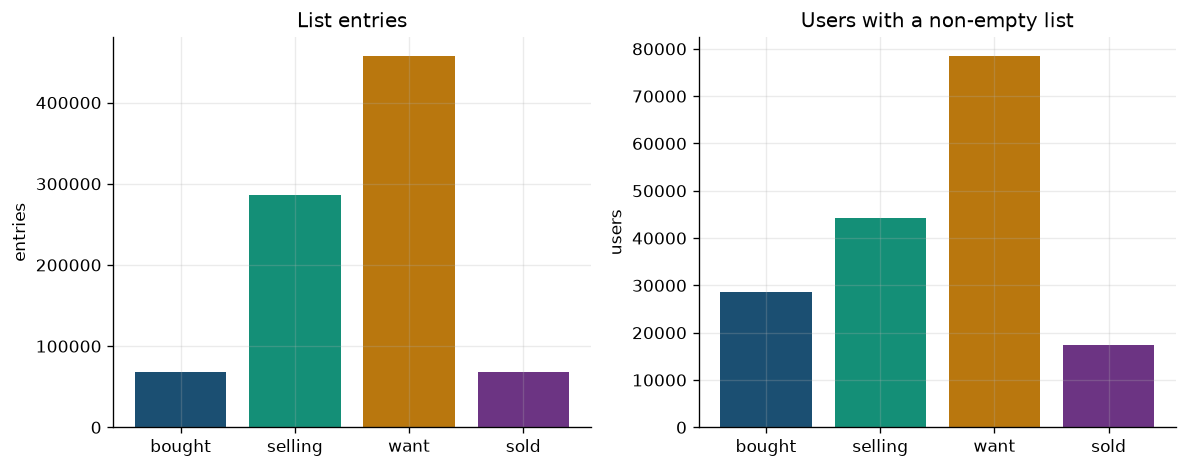

Users with at least one purchase: 28,680 of 128,152
Users with at least two purchases (leave-one-out eligible): 9,766
Users with at least two wanted items: 38,775


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(summary["action"], summary["entries"], color=[COLORS[a] for a in summary["action"]])
axes[0].set_title("List entries")
axes[0].set_ylabel("entries")
axes[1].bar(summary["action"], summary["users"], color=[COLORS[a] for a in summary["action"]])
axes[1].set_title("Users with a non-empty list")
axes[1].set_ylabel("users")
fig.tight_layout()
plt.show()

print(f"Users with at least one purchase: {(users['n_bought'] > 0).sum():,} of {len(users):,}")
print(f"Users with at least two purchases (leave-one-out eligible): {(users['n_bought'] >= 2).sum():,}")
print(f"Users with at least two wanted items: {(users['n_want'] >= 2).sum():,}")

## Most lists are short, and users do different things

A rating-style model needs repeated observations of the same user and the same item. The lengths below show how little history each user has, and the combination chart shows that many users never purchase anything. They only want items, or only offer them.

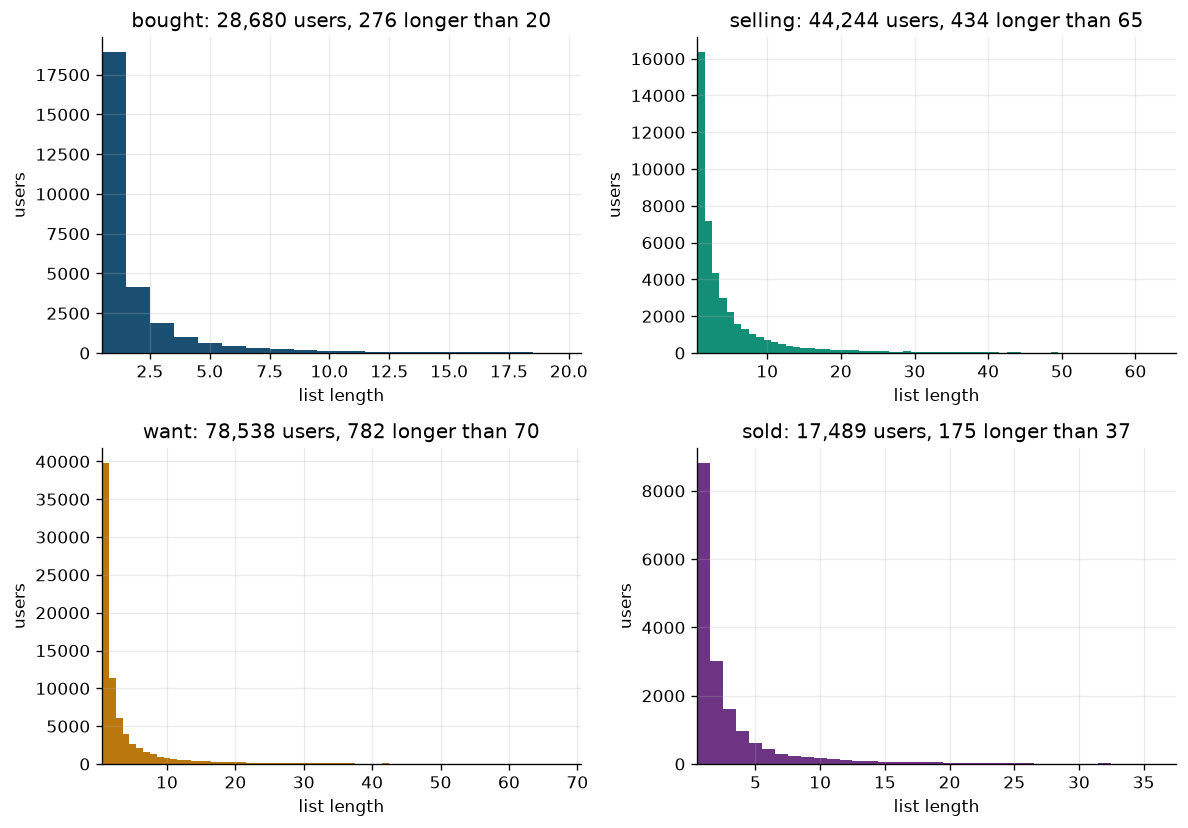

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, action in zip(axes.ravel(), ACTIONS):
    lengths = users.loc[users[f"n_{action}"] > 0, f"n_{action}"]
    cap = max(int(lengths.quantile(0.99)), 1)
    shown = lengths[lengths <= cap]
    ax.hist(shown, bins=range(1, cap + 2), color=COLORS[action], align="left")
    ax.set_xlim(0.5, cap + 0.5)
    ax.set_title(f"{action}: {len(lengths):,} users, {(lengths > cap).sum():,} longer than {cap}")
    ax.set_xlabel("list length")
    ax.set_ylabel("users")
fig.tight_layout()
plt.show()

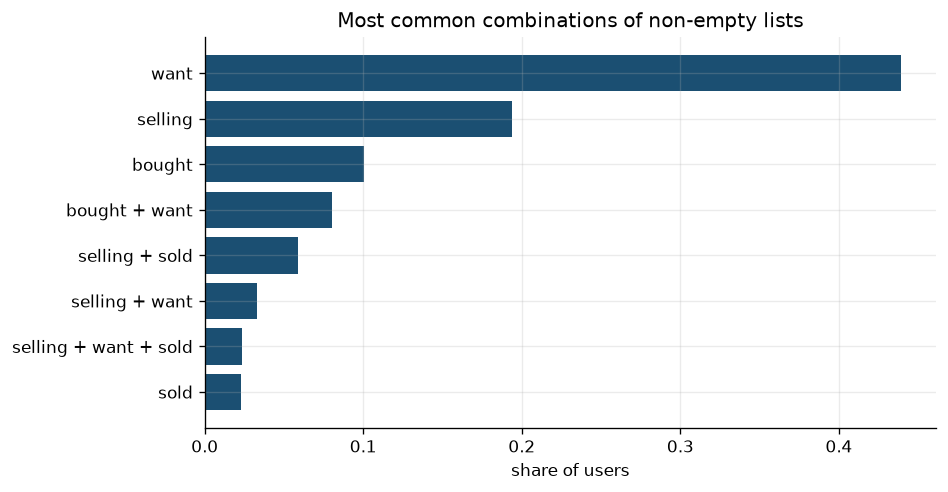

,lists_present,users,share
0,want,56294,0.439275
1,selling,24843,0.193856
2,bought,12918,0.100802
3,bought + want,10285,0.080256
4,selling + sold,7571,0.059078
5,selling + want,4201,0.032781
6,selling + want + sold,2978,0.023238
7,sold,2903,0.022653


In [14]:
users["lists_present"] = [
    " + ".join(action for action, count in zip(ACTIONS, counts) if count > 0)
    for counts in zip(users["n_bought"], users["n_selling"], users["n_want"], users["n_sold"])
]

segments = (
    users["lists_present"].value_counts()
    .rename_axis("lists_present")
    .reset_index(name="users")
)
segments["share"] = segments["users"] / len(users)
top_segments = segments.head(8)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top_segments["lists_present"][::-1], top_segments["share"][::-1], color="#1b4f72")
ax.set_xlabel("share of users")
ax.set_title("Most common combinations of non-empty lists")
fig.tight_layout()
plt.show()

top_segments

## Purchased items do not repeat. Wanted items do.

On a marketplace of one-of-a-kind listings, collaborative filtering on purchases has almost no co-occurrence to learn from. The comparison below is the main modeling constraint in this file: a bought item is almost always associated with one user, while a wanted item is often associated with several.

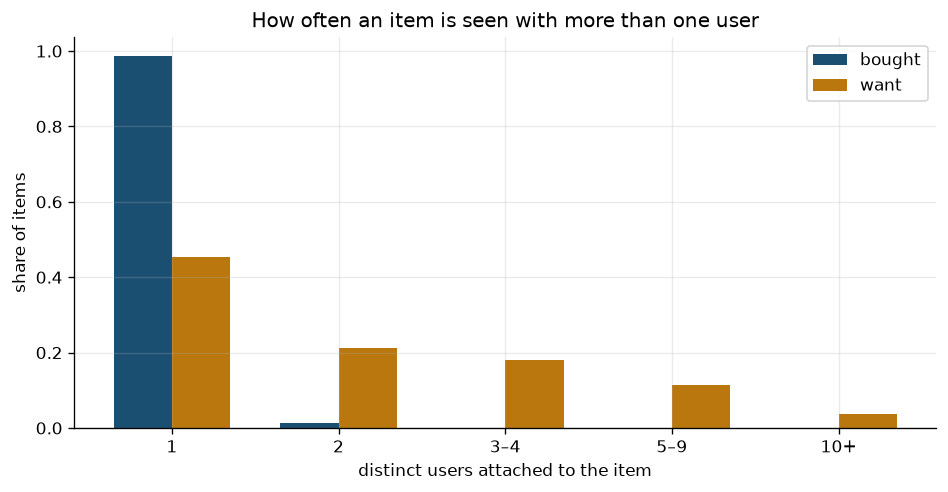

bought: median users/item 1, max 4, share with one user 98.7%
want:   median users/item 2, max 116, share with one user 45.5%
selling items with exactly one user: 100.0%


In [15]:
users_per_item = (
    interactions.groupby(["action", "item_id"])["uid"].nunique().rename("n_users").reset_index()
)

def frequency_bucket(n_users: int) -> str:
    if n_users == 1:
        return "1"
    if n_users == 2:
        return "2"
    if n_users <= 4:
        return "3–4"
    if n_users <= 9:
        return "5–9"
    return "10+"

bucket_order = ["1", "2", "3–4", "5–9", "10+"]
bucketed = users_per_item.copy()
bucketed["bucket"] = bucketed["n_users"].map(frequency_bucket)
share = (
    bucketed.groupby(["action", "bucket"]).size()
    .unstack("bucket")
    .reindex(index=ACTIONS, columns=bucket_order)
    .fillna(0)
)
share = share.div(share.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(8, 4.2))
x = range(len(bucket_order))
width = 0.35
ax.bar([i - width / 2 for i in x], share.loc["bought"], width=width, label="bought", color=COLORS["bought"])
ax.bar([i + width / 2 for i in x], share.loc["want"], width=width, label="want", color=COLORS["want"])
ax.set_xticks(list(x), bucket_order)
ax.set_xlabel("distinct users attached to the item")
ax.set_ylabel("share of items")
ax.set_title("How often an item is seen with more than one user")
ax.legend()
fig.tight_layout()
plt.show()

bought_freq = users_per_item.loc[users_per_item["action"] == "bought", "n_users"]
want_freq = users_per_item.loc[users_per_item["action"] == "want", "n_users"]
print(f"bought: median users/item {bought_freq.median():.0f}, max {bought_freq.max():.0f}, share with one user {((bought_freq == 1).mean()):.1%}")
print(f"want:   median users/item {want_freq.median():.0f}, max {want_freq.max():.0f}, share with one user {((want_freq == 1).mean()):.1%}")
print(f"selling items with exactly one user: {(users_per_item.loc[users_per_item['action'] == 'selling', 'n_users'] == 1).mean():.1%}")

## A purchase is a match between two users

The same item id shows up on the buyer's `bought` list and, for almost every purchase, on a different user's `sold` list. `selling` never shares an item across users: each active listing belongs to one account. So these ids are listings, not catalog products that many people buy.

In [16]:
buyers = interactions.loc[interactions["action"] == "bought"].groupby("item_id")["uid"].agg(set)
sellers = interactions.loc[interactions["action"] == "sold"].groupby("item_id")["uid"].agg(set)
listed_items = set(interactions.loc[interactions["action"].isin(["selling", "sold"]), "item_id"])
common_items = buyers.index.intersection(sellers.index)

same_user_items = 0
different_user_items = 0
for item_id in common_items:
    if buyers.at[item_id] & sellers.at[item_id]:
        same_user_items += 1
    else:
        different_user_items += 1

n_bought_entries = int((interactions["action"] == "bought").sum())
own_want_hits = sum(len(set(bought) & set(want)) for bought, want in zip(users["bought"], users["want"]))
want_entries = int(users["n_want"].sum())
want_that_are_listed = int(interactions.loc[interactions["action"] == "want", "item_id"].isin(listed_items).sum())

trade_stats = pd.DataFrame([
    {
        "measure": "bought entries",
        "count": n_bought_entries,
        "rate": 1.0,
        "rate_is_share_of": "bought entries",
    },
    {
        "measure": "bought items that also appear on a sold list",
        "count": len(common_items),
        "rate": len(common_items) / len(buyers),
        "rate_is_share_of": "bought items",
    },
    {
        "measure": "matched items whose buyer and seller are different users",
        "count": different_user_items,
        "rate": different_user_items / len(common_items),
        "rate_is_share_of": "bought items that were also sold",
    },
    {
        "measure": "matched items where one user is both buyer and seller",
        "count": same_user_items,
        "rate": same_user_items / len(common_items),
        "rate_is_share_of": "bought items that were also sold",
    },
    {
        "measure": "purchases that are also on that user's want list",
        "count": own_want_hits,
        "rate": own_want_hits / n_bought_entries,
        "rate_is_share_of": "bought entries",
    },
    {
        "measure": "want entries whose item is on some selling or sold list",
        "count": want_that_are_listed,
        "rate": want_that_are_listed / want_entries,
        "rate_is_share_of": "want entries",
    },
])
trade_stats

,measure,count,rate,rate_is_share_of
0,bought entries,68543,1.000000,bought entries
1,bought items that also appear on a sold list,66807,0.987276,bought items
2,matched items whose buyer and seller are diffe...,65995,0.987846,bought items that were also sold
3,matched items where one user is both buyer and...,812,0.012154,bought items that were also sold
4,purchases that are also on that user's want list,17241,0.251536,bought entries
5,want entries whose item is on some selling or ...,451995,0.987557,want entries


## What this implies for the model

The file supports an implicit-feedback recommendation task. It does not support rating regression.

Predicting `bought` directly is a weak fit to the models from the first half of the course:

- The most purchased item is bought by 4 users. A most-popular baseline on purchases has almost no head to recommend, and an item neighborhood has almost no neighbors.
- Only users with two or more purchases can support a leave-one-out test. That is a small slice of the 128,152 users.
- There is no timestamp, so a temporal train/test split is not available. A random holdout of edges is the protocol the columns allow.
- About a quarter of purchases are also on that user's `want` list. Using `want` as a feature of `bought` can leak the label, because nothing records which list was written first.

`want` is the signal that repeats. Wanted items have a median of two users, a long tail, and almost all of them refer to a listing someone is selling or has sold. That is the graph a Jaccard similarity model, or a one-class method such as BPR, can be compared against a most-popular baseline on.

**Task to carry forward.** For each of the 38,775 users with at least two wanted items, hold out one wanted item and treat the rest of that user's `want` list as the observed history. Rank a candidate set that includes the held-out item and a sample of items the user did not want. Score the ranking with HitRate@10 and AUC. Baselines from class: rank by how many users want the item, then by Jaccard similarity between the users who want the candidate and the user's history. A purchase leave-one-out would cover only 9,766 users, and 25.2% of purchases already sit on the same user's `want` list, so do not train on `bought`.

The WSDM bartering paper studies a stricter task: recommend a listing the user wants whose owner wants something the user is offering. That task uses the `selling`/`sold` side as well. It needs an explicit definition of a compatible trade and a negative sample of incompatible ones. It is a closer match to the paper and a larger modeling project than held-out want prediction. Item content (category, image features from the VBPR release) is not in this file, so either task is collaborative filtering on ids alone.